# 09 – MIRI-Daten zum Ring-Nebel: Bestandsaufnahme

**Was:** Herausfinden, welche MIRI-Bilder (mittleres Infrarot, 5–28 µm) es zu Programm 1558 gibt – Filter, Belichtung, Dateigrößen, Bildfeld im Vergleich zu NIRCam. Erst danach entscheiden, welche Filter wir mit NIRCam kombinieren.

**Warum:** MIRI sieht anderes (warmer Staub, PAH-Banden bei 7,7/11,3 µm) als NIRCam, ist aber unschärfer und deckt ein anderes Feld ab. Bevor wir rechnen, wollen wir wissen, *was* überhaupt zusammenpasst. Mikroskopie-Analogie: vor einem korrelativen Ansatz prüfen, welche Kanäle/Modalitäten dieselbe Region abdecken.

**Ergebnis:** 18 MIRI-i2d-Produkte zu Programm 1558; verwendet wird nur das Hauptmosaik o001 mit 9 Filtern (F560W–F2550W, 444 s, zusammen 0,43 GB, alle auf einem Raster mit 0,111″/px). Die Überlappung mit NIRCam enthält den ganzen Ring. Ausgewählt für die Kombination: F560W, F770W, F1500W.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import warnings
from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning

from astropipe import bands, mast, registration

warnings.simplefilter("ignore", FITSFixedWarning)
TARGET, PROGRAM = "ngc6720", 1558
ROOT = Path("..")
RAW_MIRI = ROOT / "data" / f"{TARGET}_miri"
RAW_NIRCAM = ROOT / "data" / f"{TARGET}_nircam"

## 1. Welche MIRI-Beobachtungen gibt es?

Laut Wesson et al. 2024: neun Filter (F560W … F2550W) als 1 × 2-Mosaik, dazu drei Filter (F770W, F1000W, F1130W) als *Simultanaufnahmen* während der MIRI-Spektroskopie, die nur einen Teil des äußeren Nebels zeigen. Falls beide Sorten auftauchen, sieht man es an mehreren Beobachtungen pro Filter und an abweichenden Positionen (`s_ra`, `s_dec`).

In [2]:
obs, i2d = mast.find_i2d(PROGRAM, "MIRI/IMAGE")
print(len(obs), "observations,", len(i2d), "i2d products,", f"{mast.total_size_gb(i2d):.2f} GB")
obs.sort("filters")
obs["obs_id", "filters", "t_exptime", "s_ra", "s_dec", "target_name"]

18 observations, 18 i2d products, 0.70 GB


obs_id,filters,t_exptime,s_ra,s_dec,target_name
str29,str6,float64,float64,float64,str22
jw01558-o002_t004_miri_f1000w,F1000W,921.312,283.3937916666667,33.03586388888889,NGC6720-MRS-POSITION-1
jw01558-o004_t006_miri_f1000w,F1000W,921.312,283.3885125,33.03052777777778,NGC6720-MRS-POSITION-2
jw01558-o001_t001_miri_f1000w,F1000W,444.0079999999999,283.3961625,33.029175,NGC6720
jw01558-o003_t002_miri_f1000w,F1000W,921.312,283.2868245833333,33.03052777777778,NGC6720-MRS-OFF
jw01558-o002_t004_miri_f1130w,F1130W,921.312,283.3937916666667,33.03586388888889,NGC6720-MRS-POSITION-1
jw01558-o004_t006_miri_f1130w,F1130W,921.312,283.3885125,33.03052777777778,NGC6720-MRS-POSITION-2
jw01558-o001_t001_miri_f1130w,F1130W,444.0079999999999,283.3961625,33.029175,NGC6720
jw01558-o003_t002_miri_f1130w,F1130W,921.312,283.2868245833333,33.03052777777778,NGC6720-MRS-OFF
jw01558-o001_t001_miri_f1280w,F1280W,444.0079999999999,283.3961625,33.029175,NGC6720


In [3]:
i2d.sort("productFilename")
for row in i2d:
    print(f"{row['productFilename']:<55} {row['size'] / 1e6:7.1f} MB  {row['dataRights']}")

jw01558-o001_t001_miri_f1000w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f1130w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f1280w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f1500w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f1800w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f2100w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f2550w_i2d.fits                     48.2 MB  PUBLIC
jw01558-o001_t001_miri_f560w_i2d.fits                      48.2 MB  PUBLIC
jw01558-o001_t001_miri_f770w_i2d.fits                      48.2 MB  PUBLIC
jw01558-o002_t004_miri_f1000w_i2d.fits                     29.9 MB  PUBLIC
jw01558-o002_t004_miri_f1130w_i2d.fits                     29.9 MB  PUBLIC
jw01558-o002_t004_miri_f770w_i2d.fits                      29.9 MB  PUBLIC
jw01558-o003_t002_miri_f1000w_i2d.fits                     29.9 MB  PUBLIC
jw01558-o003_t002_miri_f1

## 2. Laden

Nur ausführen, wenn die Liste oben plausibel ist. Vorhandene Dateien werden übersprungen.

In [5]:
DOWNLOAD = True   # set True after checking the list
if DOWNLOAD:
    main = i2d[["-o001_" in f for f in i2d["productFilename"]]]   # main 9-filter mosaic only
    print(len(main), "files selected")
    mast.download(main, RAW_MIRI, max_gb=5.0)
files = sorted(RAW_MIRI.glob("*_i2d.fits"))
print(len(files), "MIRI i2d files local")

9 files selected
0 of 9 files already present, 9 to download (0.43 GB)
9 MIRI i2d files local


## 3. Eckdaten pro Datei

Filter, Bildgröße, Pixelgröße, Belichtung und die Position der Bildmitte. Mehrere Dateien pro Filter sind möglich (Mosaik vs. Simultanaufnahme).

In [6]:
info = []
for f in files:
    h0, h1 = fits.getheader(f, 0), fits.getheader(f, extname="SCI")
    w = WCS(h1)
    c = w.pixel_to_world(h1["NAXIS1"] / 2, h1["NAXIS2"] / 2)
    info.append(dict(file=f.name, band=bands.band_from_header(h0), shape=(h1["NAXIS2"], h1["NAXIS1"]),
                     pix=registration.pixel_scale_arcsec(w)[0], texp=h0.get("EFFEXPTM"),
                     ra=c.ra.deg, dec=c.dec.deg, wcs=w, nx=h1["NAXIS1"], ny=h1["NAXIS2"]))
info.sort(key=lambda d: bands.wavelength_um(d["band"]))
print(f"{'band':<7}{'shape':<14}{'pix″':>7}{'t_exp':>8}{'RA':>11}{'Dec':>11}  file")
for d in info:
    print(f"{d['band']:<7}{str(d['shape']):<14}{d['pix']:7.3f}{d['texp']:8.0f}{d['ra']:11.5f}{d['dec']:11.5f}  {d['file']}")

band   shape            pix″   t_exp         RA        Dec  file
F560W  (1043, 1644)    0.111     444  283.39175   33.02513  jw01558-o001_t001_miri_f560w_i2d.fits
F770W  (1043, 1644)    0.111     444  283.39175   33.02513  jw01558-o001_t001_miri_f770w_i2d.fits
F1000W (1043, 1644)    0.111     444  283.39173   33.02514  jw01558-o001_t001_miri_f1000w_i2d.fits
F1130W (1043, 1644)    0.111     444  283.39174   33.02514  jw01558-o001_t001_miri_f1130w_i2d.fits
F1280W (1043, 1644)    0.111     444  283.39173   33.02514  jw01558-o001_t001_miri_f1280w_i2d.fits
F1500W (1043, 1644)    0.111     444  283.39172   33.02513  jw01558-o001_t001_miri_f1500w_i2d.fits
F1800W (1043, 1644)    0.111     444  283.39174   33.02515  jw01558-o001_t001_miri_f1800w_i2d.fits
F2100W (1043, 1644)    0.111     444  283.39174   33.02513  jw01558-o001_t001_miri_f2100w_i2d.fits
F2550W (1043, 1644)    0.111     444  283.39173   33.02513  jw01558-o001_t001_miri_f2550w_i2d.fits


## 4. Bildfelder: MIRI im Vergleich zu NIRCam

Die Umrisse jedes Bildes am Himmel (`calc_footprint` aus dem WCS). Nur dort, wo sich MIRI und NIRCam überlappen, ist ein gemeinsames Farbbild möglich. RA nimmt nach links zu (Osten links).

Text(0.5, 1.0, 'footprints on the sky')

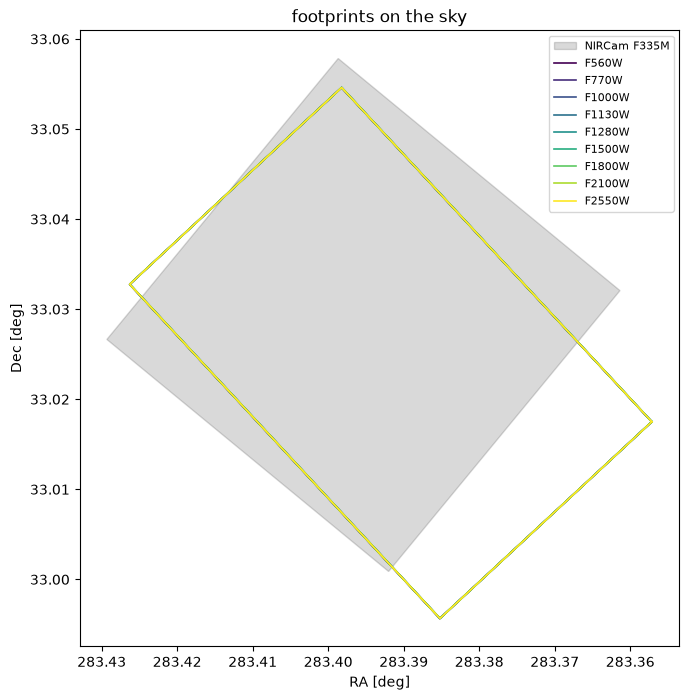

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
nircam = sorted(RAW_NIRCAM.glob("*f335m*_i2d.fits"))
if nircam:
    hn = fits.getheader(nircam[0], extname="SCI")
    fp = WCS(hn).calc_footprint(axes=(hn["NAXIS1"], hn["NAXIS2"]))
    ax.fill(*np.vstack([fp, fp[:1]]).T, alpha=0.15, color="k", label="NIRCam F335M")
cmap = plt.get_cmap("viridis")
for i, d in enumerate(info):
    fp = d["wcs"].calc_footprint(axes=(d["nx"], d["ny"]))
    ax.plot(*np.vstack([fp, fp[:1]]).T, color=cmap(i / max(1, len(info) - 1)), lw=1.2, label=d["band"])
ax.invert_xaxis()
ax.set_xlabel("RA [deg]"); ax.set_ylabel("Dec [deg]"); ax.set_aspect(1 / np.cos(np.deg2rad(33.03)))
ax.legend(fontsize=8, loc="upper right"); ax.set_title("footprints on the sky")

## 5. Schnellansicht

Jedes MIRI-Bild mit einfacher Vorschau-Streckung (Perzentile + asinh), um Inhalt, Schärfe und Artefakte einzuschätzen.

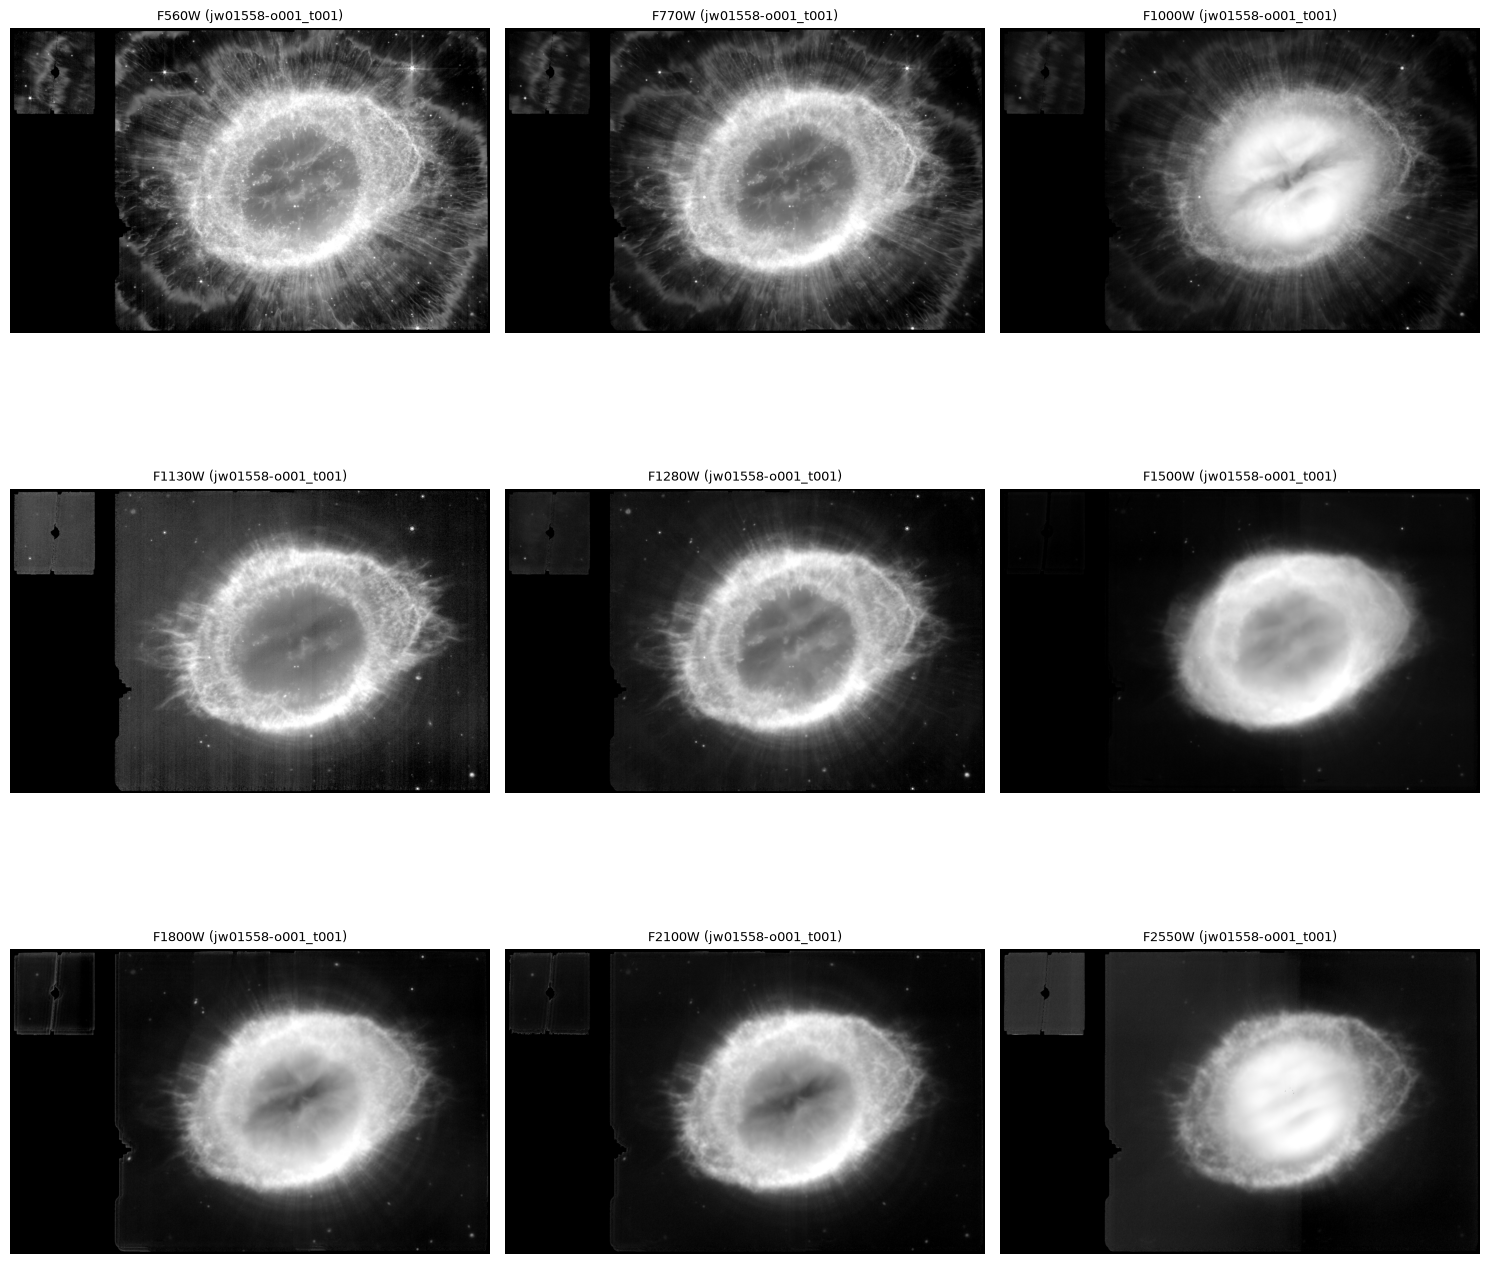

In [8]:
from astropipe.stretch import asinh_stretch

n = len(info)
cols = 3
rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(5 * cols, 5 * rows_), squeeze=False)
for ax, d in zip(axes.flat, info):
    img = fits.getdata(RAW_MIRI / d["file"], extname="SCI").astype(np.float32)
    v = img[np.isfinite(img)]
    lo, hi = np.percentile(v, [1, 99.5])
    ax.imshow(asinh_stretch(np.clip((np.nan_to_num(img, nan=lo) - lo) / (hi - lo), 0, 1), 0.05),
              origin="lower", cmap="gray")
    ax.set_title(f"{d['band']} ({d['file'][:17]})", fontsize=9)
    ax.axis("off")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()

## Fazit

- **MAST, Programm 1558, MIRI:** 18 i2d-Produkte in drei Sorten: **o001** = Hauptmosaik in 9 Filtern (F560W–F2550W, 444 s, je 48 MB); o002/o004 = Simultanaufnahmen während der MIRI-Spektroskopie (F770W/F1000W/F1130W, nur Teile des Nebels); o003 = Hintergrundposition der Spektroskopie (≈ 5,5′ abseits, leerer Himmel). Geladen: nur o001 (0,43 GB).
- Alle 9 Filter liegen auf **einem gemeinsamen Raster** (1043 × 1644 px, 0,111″/px). Filtererkennung und Sortierung mit vierstelligen Namen (F1130W) funktionieren im Paket.
- **Bildfeld:** MIRI-Mosaik gegenüber NIRCam nach Südwesten versetzt und gedreht; die Überlappung enthält den ganzen Ring. Ein kleines abgesetztes Feld oben links ist vermutlich das Koronografenfeld.
- **Inhalt** (Wesson et al. 2024, Tab. 1): kurze Filter (F560W, F770W) scharf mit H₂, Halo-Bögen und PAH; F1000W [S IV], F1280W [Ne II], F1500W fast reines [Ne III], F1800W [S III], F2550W Kontinuum (warmer Staub). Schärfe von 0,21″ (F560W) bis 0,80″ (F2550W), NIRCam ≈ 0,05–0,11″.
- **Artefakte:** senkrechte Streifen in F1130W, Helligkeitsstufe in F2550W.
- **Auswahl für die Kombination:** F560W und F770W (scharf, Halo) sowie F1500W ([Ne III], hoch ionisiertes Gas innen).